In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score

import warnings
warnings.filterwarnings('ignore')

SEED=95

In [45]:
udbhav_cols = ["checking","duration","history","purpose","amount","savings","employment","install_rate","personal_status","other_debtors","residence","property","age","other_plans","housing","existing_credits","job","dependents","telephone","foreign","class"]
udbhav_url=  "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

try:
  df=pd.read_csv(udbhav_url,sep=" ",header=None,names=udbhav_cols)
  print("loaded")

except Exception:
  df=pd.read_csv("german_data",sep=" ",header=None,names=udbhav_cols)
  print("url fetch failed")

print(f"{df.shape}")
df.head()


loaded
(1000, 21)


,checking,duration,history,purpose,amount,savings,employment,install_rate,personal_status,other_debtors,...,property,age,other_plans,housing,existing_credits,job,dependents,telephone,foreign,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [46]:
if"class" in df.columns:
  df["approve"]=(df["class"]==1).astype(int)
  df=df.drop(columns="class")
df["female"]=df["personal_status"].isin(["A92","A95"]).astype(int)
df["young"]=(df["age"]<=25).astype(int)
print(df["approve"].value_counts())
print(df.shape)
print("this is the gender rate approval (1=female,0=male)")
print(df.groupby("female")["approve"].mean())
print("this is the by age group(1<=25,0=older)")
print(df.groupby("young")["approve"].mean())


approve
1    700
0    300
Name: count, dtype: int64
(1000, 23)
this is the gender rate approval (1=female,0=male)
female
0    0.723188
1    0.648387
Name: approve, dtype: float64
this is the by age group(1<=25,0=older)
young
0    0.728395
1    0.578947
Name: approve, dtype: float64


In [47]:
# now the preprocessing will start after coming of all of the incredients.

df.replace("?",pd.NA,inplace=True)
miss_udbhav_c=df.isna().sum()
print("This is per columns counts")
c_obj=miss_udbhav_c[miss_udbhav_c>0]
print(c_obj)


This is per columns counts
Series([], dtype: int64)


In [48]:
uddu_cols=["duration","amount","install_rate","residence","age","existing_credits"]
print("full_summary_features")

for ud in uddu_cols:
  a,b=df[ud].quantile([0.25,0.75])
  rem=b-a
  out_lu=df[(df[ud]<a-1.5*rem)|(df[ud]>b+1.5*rem)][ud]
  sky=df[ud].skew()
  print("i am finding the outlierts")
  print(f"{ud:<16}| skew:{sky:>5.2f}|outlier_cu:{out_lu})")
df["log_amount"]=np.log(df["amount"]+1)
print("all results after transform:{df[out_lu].skwe():.2f}")




full_summary_features
i am finding the outlierts
duration        | skew: 1.09|outlier_cu:1      48
11     48
29     60
35     45
36     48
       ..
945    48
973    60
981    48
998    45
999    45
Name: duration, Length: 70, dtype: int64)
i am finding the outlierts
amount          | skew: 1.95|outlier_cu:5       9055
17      8072
18     12579
57      9566
63     14421
       ...  
927    10297
945     8358
953    10974
980     8386
983     8229
Name: amount, Length: 72, dtype: int64)
i am finding the outlierts
install_rate    | skew:-0.53|outlier_cu:Series([], Name: install_rate, dtype: int64))
i am finding the outlierts
residence       | skew:-0.27|outlier_cu:Series([], Name: residence, dtype: int64))
i am finding the outlierts
age             | skew: 1.02|outlier_cu:0      67
75     66
137    66
163    70
179    65
186    74
187    68
213    66
330    75
430    74
438    65
536    75
554    67
606    74
624    65
723    66
756    74
774    66
779    67
807    65
846    68
883    65

In [49]:
catking_cols=["checking","history","purpose","savings","employment","personal_status","other_debtors","property","other_plans","housing","job","telephone","foreign"]
feasts_numbers=["duration","log_amount","install_rate","residence","age","existing_credits","dependents"]
ab=pd.concat([df[feasts_numbers],pd.get_dummies(df[catking_cols],drop_first=True).astype(float)],axis=1)
b=df["approve"]



x_train,x_test,y_train,y_test=train_test_split(ab,b,test_size=0.30,random_state=SEED)
scaler=StandardScaler()
x_train[feasts_numbers]=scaler.fit_transform(x_train[feasts_numbers])
x_test[feasts_numbers]=scaler.transform(x_test[feasts_numbers])






x_train=sm.add_constant(x_train,has_constant='add')
x_test=sm.add_constant(x_test,has_constant='add')


print("completed")

print("shape")
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)



completed
shape
(700, 49)
(300, 49)
(700,)
(300,)


In [50]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score,roc_auc_score
SEED=95
lpu=LinearRegression().fit(x_train,y_train)
logistic_model=LogisticRegression(random_state=SEED,max_iter=1000).fit(x_train,y_train)
predm_u=lpu.predict(x_test)
prob_l=logistic_model.predict_proba(x_test)[:,1]
print(f"R-squared:{lpu.score(x_train,y_train):.3f}")
print(f"ROC_AUC:{roc_auc_score(y_test,predm_u):.3f}|Logistic Regression:{roc_auc_score(y_test,prob_l):.3f}")



R-squared:0.298
ROC_AUC:0.783|Logistic Regression:0.786


In [51]:

import pandas as pd
import numpy as np



eval_df=pd.DataFrame({
    'y_true':y_test.values,
    'lpm_score':predm_u,
    'logit_prob':prob_l,



})

eval_df['lpm_decile']=pd.qcut(eval_df['lpm_score'],q=10,labels=False,duplicates='drop')
eval_df['logit_decile']=pd.qcut(eval_df['logit_prob'],q=10,labels=False,duplicates='drop')

decile_sum=eval_df.groupby('logit_decile').agg(
    Total_Bu=('y_true','count'),
    Actual_Bu=('y_true','mean'),
    Mean_logis=('logit_prob','mean'),
    Mean_lpm=('lpm_score','mean')


).reset_index()

print("="*75)
print("Decline")
print("="*75)
print(decile_sum.to_string(index=False,formatters={
    'Total_Bu':'{:.1%}'.format,
    'Actual_Bu':'{:.1%}'.format,
    'Mean_Logis':'{:.1%}'.format,
    'Mean_lpm':'{:.1%}'.format
}))





Decline
 logit_decile Total_Bu Actual_Bu  Mean_logis Mean_lpm
            0  3000.0%     26.7%    0.196879    23.8%
            1  3000.0%     46.7%    0.410632    44.0%
            2  3000.0%     56.7%    0.535107    53.8%
            3  3000.0%     60.0%    0.638214    61.5%
            4  3000.0%     60.0%    0.726608    67.5%
            5  3000.0%     90.0%    0.818304    75.5%
            6  3000.0%     83.3%    0.882385    83.8%
            7  3000.0%     83.3%    0.920646    92.2%
            8  3000.0%     90.0%    0.951679    99.3%
            9  3000.0%    100.0%    0.977437   113.6%


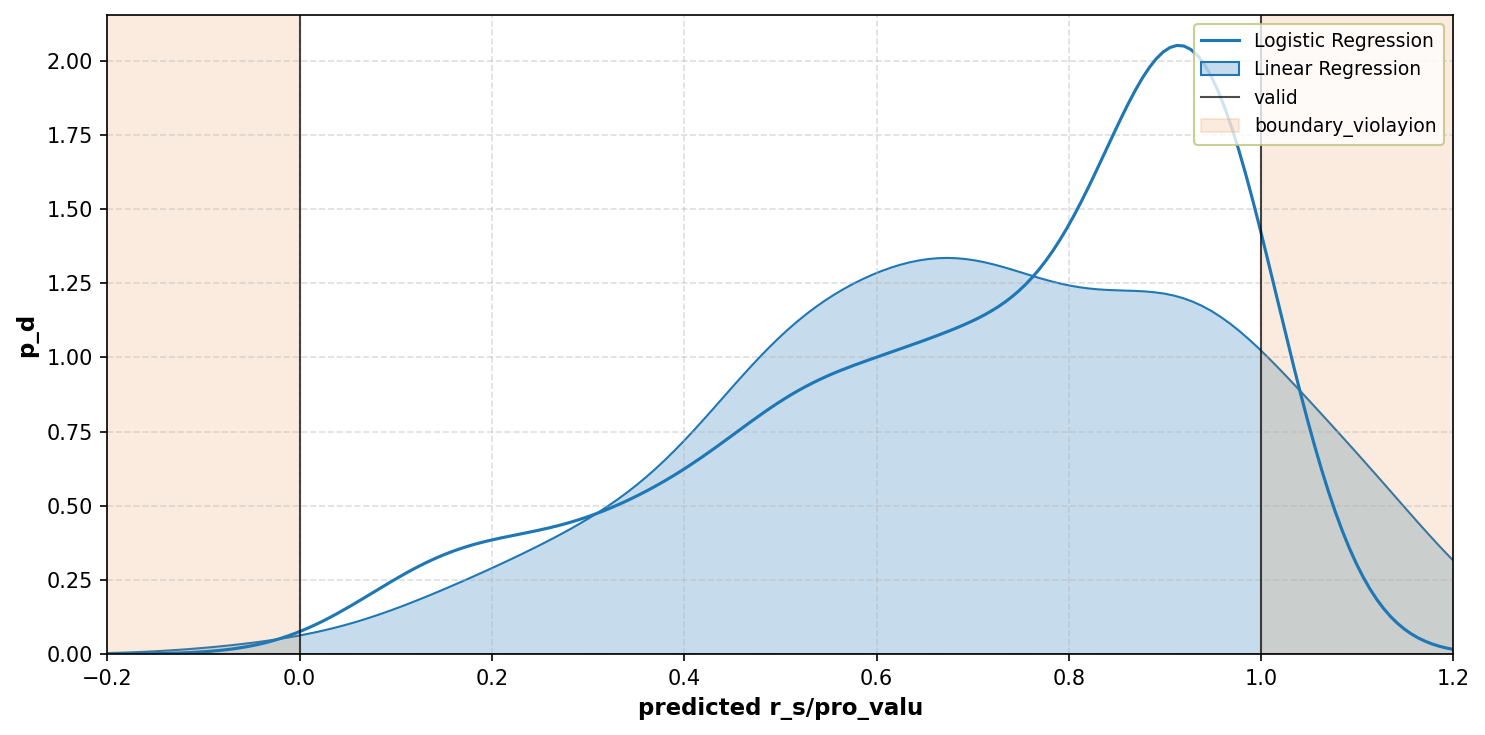

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,5),dpi=150)
sns.kdeplot(prob_l,label="Logistic Regression")
sns.kdeplot(predm_u,fill=True,label="Linear Regression")
plt.axvline(0.0,color='black',linewidth=1,alpha=0.7,label="valid")
plt.axvline(1.0,color='black',linewidth=1,alpha=0.7)
plt.axvspan(-0.3,0.0,color="#e67e22",alpha=0.15,label="boundary_violayion")
plt.axvspan(1.0,1.3,color="#e67e22",alpha=0.15)
plt.xlabel("predicted r_s/pro_valu",fontsize=11,fontweight='semibold')
plt.ylabel("p_d",fontsize=11,fontweight='semibold')
plt.xlim(-0.2,1.2)

plt.legend(frameon=True,facecolor='white',edgecolor='#bdc37c',fontsize=9,loc='upper right')
plt.grid(True,linestyle='--',alpha=0.4)
plt.tight_layout()
plt.show()


Now we are going to have gender comparison
Cohort        Female Group  Male Group
Feature                               
age                 0.4526      0.0625
duration           -0.5529     -0.4351
install_rate       -0.2879     -0.1168
log_amount          0.0111     -0.0258


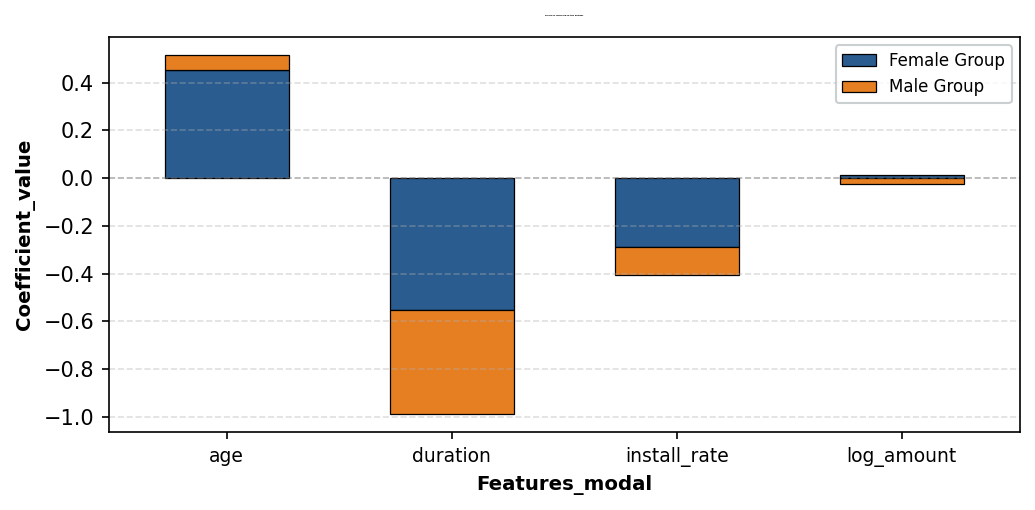

In [53]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

if 'num_feats' not in globals() or len(feasts_numbers)!=7:
  num_feats=["duration","log_amount","install_rate","residence","age","existing_credits","dependents"]
Xf_ud=pd.concat([df[num_feats],pd.get_dummies(df[catking_cols],drop_first=True).astype(float)],axis=1)
if 'scaler' in globals():
  Xf_ud[num_feats]=scaler.transform(Xf_ud[num_feats])
target_features=["age","duration","log_amount","install_rate"]

subsets={
    "Female Group": df.index[df.female==1],
    "Male Group": df.index[df.female==0],


}
results_list=[]
for group_name,index_rows in subsets.items():
  fit_res=sm.Logit(b[index_rows],sm.add_constant(Xf_ud.loc[index_rows,target_features])).fit(disp=0)
  for f in target_features:
    results_list.append(
        {
            "Cohort":group_name,
            "Feature":f,
            "Coefficient":fit_res.params[f],
            "p_value":fit_res.pvalues[f]
        }
    )
comparison_df=pd.DataFrame(results_list)
pivot_res=comparison_df.pivot(index="Feature",columns="Cohort",values='Coefficient').round(4)
print("="*55)
print("Now we are going to have gender comparison")
print("="*60)
print(pivot_res)
print("="*60)

plt.figure(figsize=(7,3.5),dpi=150)
pivot_res.plot(kind='bar',stacked='True',ax=plt.gca(),width=0.55,color=['#2b5c8f','#e67e22'],edgecolor='black',linewidth=0.6)


plt.axhline(0,color='black',linestyle='--',linewidth=0.8,alpha=0.2)
plt.title("Fairness checking in the gender",fontsize='0.5',fontweight='bold',pad=10)
plt.xlabel("Features_modal",fontsize=9.5,fontweight='semibold')
plt.ylabel("Coefficient_value",fontsize=9.5,fontweight='semibold')
plt.xticks(rotation=0,fontsize=9)




plt.grid(True,linestyle='--',alpha=0.4,axis='y')
plt.legend(frameon=True,facecolor='white',edgecolor='#bdc3c7',fontsize=8)

plt.tight_layout()
plt.show()



In [54]:
import statsmodels.api as sm
import pandas as pd

lpm_results_list=[]
for group_name,index_rows in subsets.items():
  fit_lpm=sm.OLS(b[index_rows],sm.add_constant(Xf_ud.loc[index_rows,target_features])).fit()
  for f in target_features:
    lpm_results_list.append({
        "Co":group_name,
        "Feature_ud":f,
        "Lpm_c":fit_lpm.params[f],
        "lpm_p":fit_lpm.pvalues[f]
    }
    )

pm_comparison_df=pd.DataFrame(lpm_results_list)
pm_p=pm_comparison_df.pivot(index="Feature_ud",columns="Co",values="Lpm_c").round(4)
print("="*50)
print("LPM  model subgroup comparison")
print("="*60)
print(pm_comparison_df)
print("="*45)


LPM  model subgroup comparison
             Co    Feature_ud     Lpm_c     lpm_p
0  Female Group           age  0.080644  0.001870
1  Female Group      duration -0.118799  0.004269
2  Female Group    log_amount  0.004902  0.902547
3  Female Group  install_rate -0.055390  0.042407
4    Male Group           age  0.010752  0.541449
5    Male Group      duration -0.091940  0.000055
6    Male Group    log_amount -0.002878  0.908377
7    Male Group  install_rate -0.019106  0.335182


In [55]:
import statsmodels.api as sm

full = sm.Logit(df['approve'], Xf_ud).fit(disp=0)

In [56]:
from sklearn.tree import DecisionTreeClassifier,export_text
import pandas as pd

required_udbhav=['full','Xf_ud','df']
missinf_vars=[v for v in required_udbhav if v not in globals()]
if missinf_vars:
  raise NameError(f" mIssing reqiresd:{missinf_vars}")

analysis_ud=df.copy()
analysis_ud["p"]=full.predict()
analysis_ud["pred"]=(analysis_ud["p"]>=0.5).astype(int)

target_col= 'approve' if 'approve' in  analysis_ud.columns else analysis_ud.columns[0]
analysis_ud["is_error"]=(analysis_ud["pred"]!=analysis_ud[target_col]).astype(int)
print("="*60)

print(f"Total:{len(analysis_ud)}")
print(f"total_modal errors:{analysis_ud['is_error'].sum()}({100*analysis_ud['is_error'].mean():.1f}%error rate)")
print("="*60)
tree_features=[col for col in Xf_ud.columns if col!='const' and col in analysis_ud.columns]
X_err=analysis_ud[tree_features]
y_err=analysis_ud["is_error"]

current_seed=SEED if 'SEED' in globals() else 95
error_tree=DecisionTreeClassifier(max_depth=3,random_state=current_seed)
error_tree.fit(X_err,y_err)
print("DT")
print(export_text(error_tree,feature_names=list(tree_features),max_depth=3))
print("="*70)

Total:1000
total_modal errors:225(22.5%error rate)
DT
|--- age <= 22.50
|   |--- log_amount <= 6.56
|   |   |--- class: 1
|   |--- log_amount >  6.56
|   |   |--- duration <= 16.50
|   |   |   |--- class: 0
|   |   |--- duration >  16.50
|   |   |   |--- class: 1
|--- age >  22.50
|   |--- log_amount <= 8.97
|   |   |--- duration <= 7.50
|   |   |   |--- class: 0
|   |   |--- duration >  7.50
|   |   |   |--- class: 0
|   |--- log_amount >  8.97
|   |   |--- age <= 28.50
|   |   |   |--- class: 1
|   |   |--- age >  28.50
|   |   |   |--- class: 0



In [57]:
subgroup_auditoru=analysis_ud.groupby('young').agg(
    total_u=('approve','count'),
    modal_u=('pred','mean'),
    a_a_r=('approve','mean'),
    subgroup_accuracy=('is_error','mean'),
    subgroup_ud=('is_error',lambda x:(x==0).mean())
).rename(index={0:'old',1:'young'})
print(subgroup_auditoru.round(3))



       total_u  modal_u  a_a_r  subgroup_accuracy  subgroup_ud
young                                                         
old        810    0.804  0.728              0.199        0.801
young      190    0.632  0.579              0.337        0.663


In [58]:
eval_uu=test if 'test' in globals() else analysis_ud
f_u=eval_uu[(eval_uu['pred']==1&(eval_uu['approve']==0))]
t_u=eval_uu[(eval_uu['pred']==0&(eval_uu['approve']==0))]
print("="*80)
print("comparisons of fp vs correctr")
print("="*70)
if len(f_u)>0:
  summary_df=pd.DataFrame({
      f'False Positives (n={len(f_u)})':[
          f_u['duration'].mean(),
          (f_u['checking']!='A11').mean(),
          f_u['history'].isin(['A30','A34']).mean()


      ],
      f'Correct rejections (n={len(t_u)})':[
          t_u['duration'].mean(),
          (t_u['checking']!='A11').mean(),
          t_u['history'].isin(['A30','A34']).mean()
      ]

  },index=['AVD(mo)','Chcecking (%)','chistory(%)'])
  print(summary_df.round(3))
else:
  print("No false positives")
print("="*67)


comparisons of fp vs correctr
               False Positives (n=225)  Correct rejections (n=229)
AVD(mo)                         23.053                      28.013
Chcecking (%)                    0.636                       0.402
chistory(%)                      0.253                       0.192


In [59]:
eval_df = test if 'test' in globals() else analysis_ud
ud_bhava,yu_ct,pu=(eval_df['young']==1).values,eval_df['approve'].values,eval_df['p'].values
rishabh=[]
for uuu in np.arange(0.05,1.0,0.1):
  th_u=round(uuu,2)
  pr_uu=(pu>=th_u).astype(int)

  ss=lambda s:pr_uu[s].mean()
  t_u=lambda s:pr_uu[s&(yu_ct==1)].mean()
  f_u=lambda s:pr_uu[s&(yu_ct==0)].mean()
  ppp=lambda s:yu_ct[s&(pr_uu==1)].mean()



  safer_u=lambda a,b:a/b if b>0 else 0.0


  rishabh.append({
      'Threshold':th_u,
      'Dif': safer_u(ss(ud_bhava),ss(~ud_bhava)),
      'Eq':min(safer_u(t_u(ud_bhava),ss(~ud_bhava)),safer_u(f_u(ud_bhava),(f_u(~ud_bhava)))),
      'p':ppp(ud_bhava),
      'n':ppp(~ud_bhava)
})
show_r=pd.DataFrame(rishabh)
print(show_r)





   Threshold       Dif        Eq         p         n
0       0.05  1.001236  1.001236  0.578947  0.729295
1       0.15  0.986693  0.983092  0.597826  0.739623
2       0.25  0.972689  0.991803  0.622857  0.761408
3       0.35  0.897507  0.928808  0.664474  0.790859
4       0.45  0.846362  0.924000  0.688889  0.816176
5       0.55  0.766954  0.916667  0.720721  0.849271
6       0.65  0.728612  0.697183  0.808511  0.870909
7       0.75  0.707464  0.812500  0.831169  0.905172
8       0.85  0.570073  0.750000  0.869565  0.936047
9       0.95  0.207237  0.306818  0.857143  0.986111


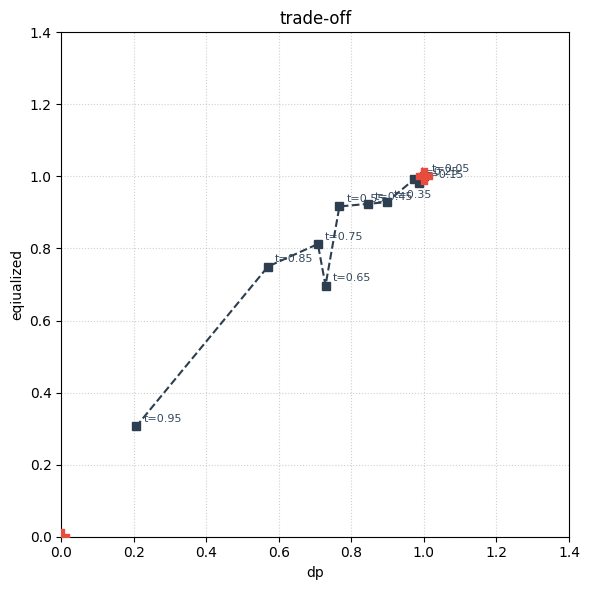

In [66]:
ud_fig,ax=plt.subplots(figsize=(6,6))
ax.plot(show_r['Dif'],show_r['Eq'],'s--',c='#2c3e50',lw=1.5,label='Threshold Path')
for r in show_r.itertuples():
  ax.annotate(f"t={r.Threshold:.2f}",(r.Dif,r.Eq),textcoords='offset points',xytext=(5,3),fontsize=8,color='#34495e')
ax.scatter([1,0],[1,0],marker='P',s=140,c='#e74c3c',label='Ideal Target',zorder=5)
ax.set(xlim=(0,1.4),ylim=(0,1.4),xlabel="dp",ylabel="eqiualized",title="trade-off")
ax.grid(ls=':',alpha=0.6)
plt.tight_layout()
plt.show()

In [32]:
print("FP Pred values:", eval_uu.loc[(eval_uu['pred'] == 1) & (eval_uu['approve'] == 0), 'pred'].unique())
print("TN Pred values:", eval_uu.loc[(eval_uu['pred'] == 0) & (eval_uu['approve'] == 0), 'pred'].unique())

FP Pred values: [1]
TN Pred values: [0]


In [70]:
udd_high = show_r[show_r['Threshold'] == 0.65].iloc[0]
udd_low  = show_r[show_r['Threshold'] == 0.55].iloc[0]

chg_p  = float((udd_low['p'] - udd_high['p']) / udd_high['p'] * 100)
chg_eq = float((udd_low['Eq'] - udd_high['Eq']) / udd_high['Eq'] * 100)
chg_df = float((udd_low['Dif'] - udd_high['Dif']) / udd_high['Dif'] * 100)

print(f"Shift 65->55 | p: {float(udd_high['p']):.3f} to {float(udd_low['p']):.3f} ({chg_p:+.1f}%) | Eq: {float(udd_high['Eq']):.3f} to {float(udd_low['Eq']):.3f} ({chg_eq:+.1f}%) | Dif: {chg_df:+.1f}%")

Shift 65->55 | p: 0.809 to 0.721 (-10.9%) | Eq: 0.697 to 0.917 (+31.5%) | Dif: +5.3%
